# Test matrices generated by the PEG algorithm

In [1]:
from coder.Coder import Coder
from decoder.Decoder import Decoder
from PEG.PEG import PEG
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor

In [ ]:
PEG(1000, 1500, 20).peg()

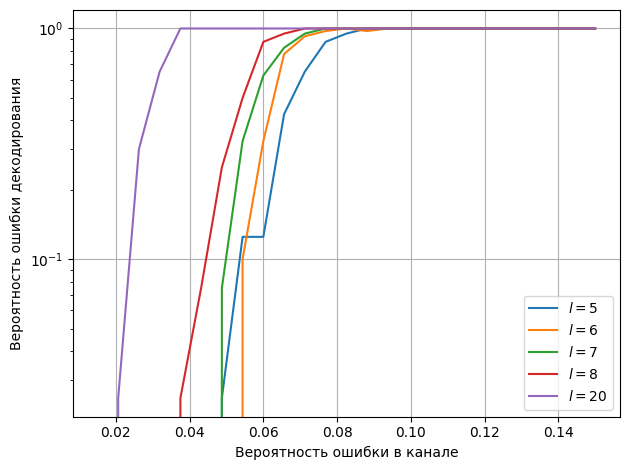

In [ ]:
def bitflipping(l):
    H = np.loadtxt(f'data/H_matrix/H{l}_1000x1500.txt', delimiter=',', dtype=np.int8)
    c = Coder.get_message(H)
    k = 25
    repeat = 40
    deep = 100
    p = np.linspace(0.015, 0.15, k)
    p_decode = Decoder.bitflipping_decoding_for_many(H, c, p, repeat, deep)
    return p, p_decode, l

l_list = list(range(5, 9)) + [20]

with ThreadPoolExecutor() as executor:
    results = list(executor.map(bitflipping, l_list))


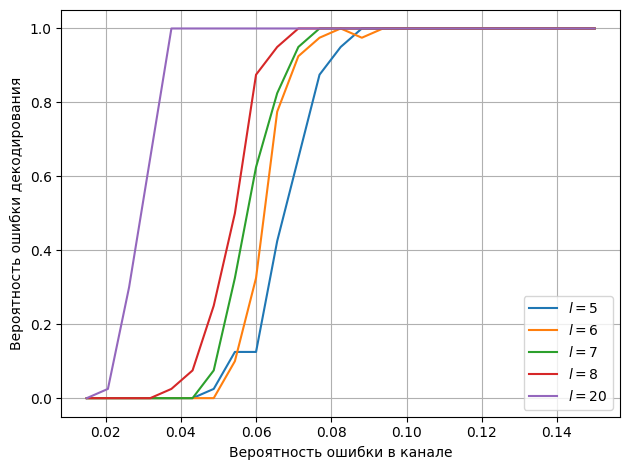

In [5]:
for p, p_decode, l in results:
    plt.plot(p, p_decode, label=f'$l = {l}$')
plt.legend()
plt.ylabel('Вероятность ошибки декодирования')
plt.xlabel('Вероятность ошибки в канале')
# plt.yscale('log')
plt.grid()
plt.tight_layout()
plt.savefig('data/H.pdf')
plt.show()